In [1]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

In [2]:
def plot_metric(data, metric_name, ylabel, groupby_col, groupby_name):
    groups = data.groupby(groupby_col)[[metric_name, "train/global_step"]]
    for (groupby_col), group in groups:
        steps = group["train/global_step"].to_list()
        exact_match = group[metric_name].to_list()
        label = f"{groupby_name}: {groupby_col}"
        plt.plot(steps, exact_match, label=label, linewidth=2)

    plt.xlabel("Step", fontsize=18)
    plt.ylabel(ylabel, fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=14)
    plt.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        fontsize=16,
        ncol=3,
        frameon=False,
    )
    plt.tight_layout()
    plt.show()

In [3]:
data = get_runs_data(
    tag="embedded-conditions",
    project="memorization",
    metrics=[
        "train/exact_match_repeated",
        "train/loss_total",
    ],
)
show_config_differences(data)

Found 3 runs with tag 'embedded-conditions'


,cfg.dataset.npz_path,cfg.dataset_metadata.target_level
_run_id,,
na60cuky,datasets/dataset_comparison_level_1.npz,1
serogenq,datasets/dataset_comparison_level_0.npz,0
vweabtjd,datasets/dataset_comparison_level_2a.npz,2a


In [4]:
for col in data.columns:
    if "cfg.dataset" in col:
        print(col)

cfg.dataset._target_
cfg.dataset.npz_path
cfg.dataset_metadata.seq_len
cfg.dataset_metadata.prefix_len
cfg.dataset_metadata.vocab_size
cfg.dataset_metadata.num_samples
cfg.dataset_metadata.target_level
cfg.dataset_metadata.model_vocab_size


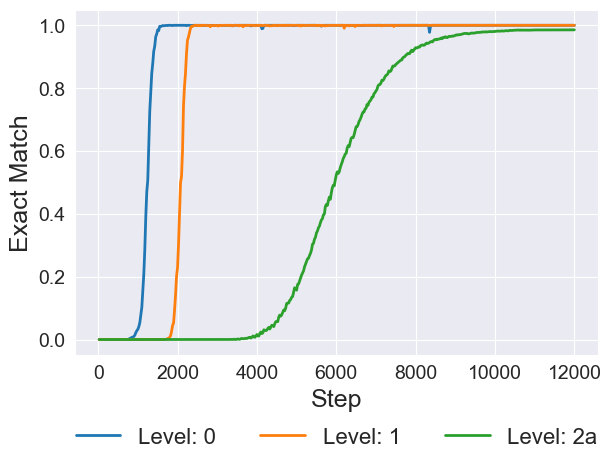

In [5]:
plot_metric(
    data, 
    "train/exact_match_repeated", 
    "Exact Match", 
    groupby_col="cfg.dataset_metadata.target_level", 
    groupby_name="Level"
)